In [1]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv("/kaggle/input/datasets/pratikgarai/mobile-phone-specifications-and-prices/ndtv_data_final.csv")
df.head()

,Unnamed: 0,Name,Brand,Model,Battery capacity (mAh),Screen size (inches),Touchscreen,Resolution x,Resolution y,Processor,RAM (MB),Internal storage (GB),Rear camera,Front camera,Operating system,Wi-Fi,Bluetooth,GPS,Number of SIMs,3G,4G/ LTE,Price
0,0,OnePlus 7T Pro McLaren Edition,OnePlus,7T Pro McLaren Edition,4085,6.67,Yes,1440,3120,8,12000,256.0,48.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,58998
1,1,Realme X2 Pro,Realme,X2 Pro,4000,6.50,Yes,1080,2400,8,6000,64.0,64.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,27999
2,2,iPhone 11 Pro Max,Apple,iPhone 11 Pro Max,3969,6.50,Yes,1242,2688,6,4000,64.0,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,106900
3,3,iPhone 11,Apple,iPhone 11,3110,6.10,Yes,828,1792,6,4000,64.0,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,62900
4,4,LG G8X ThinQ,LG,G8X ThinQ,4000,6.40,Yes,1080,2340,8,6000,128.0,12.0,32.0,Android,Yes,Yes,Yes,1,No,No,49990


In [3]:
df.shape
df.info()
df.describe(include='all')
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1359 entries, 0 to 1358
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              1359 non-null   int64  
 1   Name                    1359 non-null   object 
 2   Brand                   1359 non-null   object 
 3   Model                   1359 non-null   object 
 4   Battery capacity (mAh)  1359 non-null   int64  
 5   Screen size (inches)    1359 non-null   float64
 6   Touchscreen             1359 non-null   object 
 7   Resolution x            1359 non-null   int64  
 8   Resolution y            1359 non-null   int64  
 9   Processor               1359 non-null   int64  
 10  RAM (MB)                1359 non-null   int64  
 11  Internal storage (GB)   1359 non-null   float64
 12  Rear camera             1359 non-null   float64
 13  Front camera            1359 non-null   float64
 14  Operating system        1359 non-null   

Unnamed: 0                0
Name                      0
Brand                     0
Model                     0
Battery capacity (mAh)    0
Screen size (inches)      0
Touchscreen               0
Resolution x              0
Resolution y              0
Processor                 0
RAM (MB)                  0
Internal storage (GB)     0
Rear camera               0
Front camera              0
Operating system          0
Wi-Fi                     0
Bluetooth                 0
GPS                       0
Number of SIMs            0
3G                        0
4G/ LTE                   0
Price                     0
dtype: int64

In [4]:
df.columns.tolist()

['Unnamed: 0',
 'Name',
 'Brand',
 'Model',
 'Battery capacity (mAh)',
 'Screen size (inches)',
 'Touchscreen',
 'Resolution x',
 'Resolution y',
 'Processor',
 'RAM (MB)',
 'Internal storage (GB)',
 'Rear camera',
 'Front camera',
 'Operating system',
 'Wi-Fi',
 'Bluetooth',
 'GPS',
 'Number of SIMs',
 '3G',
 '4G/ LTE',
 'Price']

In [5]:
df.columns = (
    df.columns
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("/", "_")
)

df.columns

Index(['unnamed:_0', 'name', 'brand', 'model', 'battery_capacity_mah',
       'screen_size_inches', 'touchscreen', 'resolution_x', 'resolution_y',
       'processor', 'ram_mb', 'internal_storage_gb', 'rear_camera',
       'front_camera', 'operating_system', 'wi-fi', 'bluetooth', 'gps',
       'number_of_sims', '3g', '4g__lte', 'price'],
      dtype='object')

In [6]:
df = df.drop(columns=['unnamed:_0'])

In [7]:
df['ram_gb'] = df['ram_mb'] / 1024

In [8]:
df['ppi'] = (
    np.sqrt(df['resolution_x']**2 + df['resolution_y']**2)
    / df['screen_size_inches']
)

In [9]:
def extract_mp(text):
    if pd.isna(text):
        return np.nan
    match = re.search(r'\d+', str(text))
    return int(match.group()) if match else np.nan

df['rear_camera_mp'] = df['rear_camera'].apply(extract_mp)
df['front_camera_mp'] = df['front_camera'].apply(extract_mp)

In [10]:
df['price'].describe()

count      1359.000000
mean      11465.825607
std       13857.497077
min         494.000000
25%        4763.500000
50%        6999.000000
75%       11999.000000
max      174990.000000
Name: price, dtype: float64

In [11]:
cols = [
    'ram_gb','internal_storage_gb','battery_capacity_mah',
    'screen_size_inches','ppi','rear_camera_mp','front_camera_mp','price'
]

for col in cols:
    df[col] = df[col].fillna(df[col].median())

In [12]:
from sklearn.preprocessing import MinMaxScaler

features = [
    'ram_gb',
    'internal_storage_gb',
    'battery_capacity_mah',
    'ppi',
    'rear_camera_mp'
]

scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df[features])

df['tech_score'] = df_scaled.mean(axis=1)

In [13]:
df['value_score'] = df['tech_score'] / df['price']

In [14]:
df.head()

,name,brand,model,battery_capacity_mah,screen_size_inches,touchscreen,resolution_x,resolution_y,processor,ram_mb,internal_storage_gb,rear_camera,front_camera,operating_system,wi-fi,bluetooth,gps,number_of_sims,3g,4g__lte,price,ram_gb,ppi,rear_camera_mp,front_camera_mp,tech_score,value_score
0,OnePlus 7T Pro McLaren Edition,OnePlus,7T Pro McLaren Edition,4085,6.67,Yes,1440,3120,8,12000,256.0,48.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,58998,11.718750,515.183966,48,16,0.627552,0.000011
1,Realme X2 Pro,Realme,X2 Pro,4000,6.50,Yes,1080,2400,8,6000,64.0,64.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,27999,5.859375,404.893148,64,16,0.445602,0.000016
2,iPhone 11 Pro Max,Apple,iPhone 11 Pro Max,3969,6.50,Yes,1242,2688,6,4000,64.0,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,106900,3.906250,455.548515,12,12,0.329536,0.000003
3,iPhone 11,Apple,iPhone 11,3110,6.10,Yes,828,1792,6,4000,64.0,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,62900,3.906250,323.613699,12,12,0.256077,0.000004
4,LG G8X ThinQ,LG,G8X ThinQ,4000,6.40,Yes,1080,2340,8,6000,128.0,12.0,32.0,Android,Yes,Yes,Yes,1,No,No,49990,5.859375,402.688717,12,32,0.373656,0.000007


In [15]:
df['price_usd'] = df['price'] / 83

In [16]:
df[['price','price_usd']].head()

,price,price_usd
0,58998,710.819277
1,27999,337.337349
2,106900,1287.951807
3,62900,757.831325
4,49990,602.289157


In [17]:
def price_segment(price):
    if price < 300:
        return 'Budget'
    elif price < 600:
        return 'Mid-range'
    elif price < 900:
        return 'Flagship'
    else:
        return 'Premium'

In [18]:
df['segment'] = df['price_usd'].apply(price_segment)

In [19]:
df['segment'].value_counts()

segment
Budget       1230
Mid-range      87
Flagship       32
Premium        10
Name: count, dtype: int64

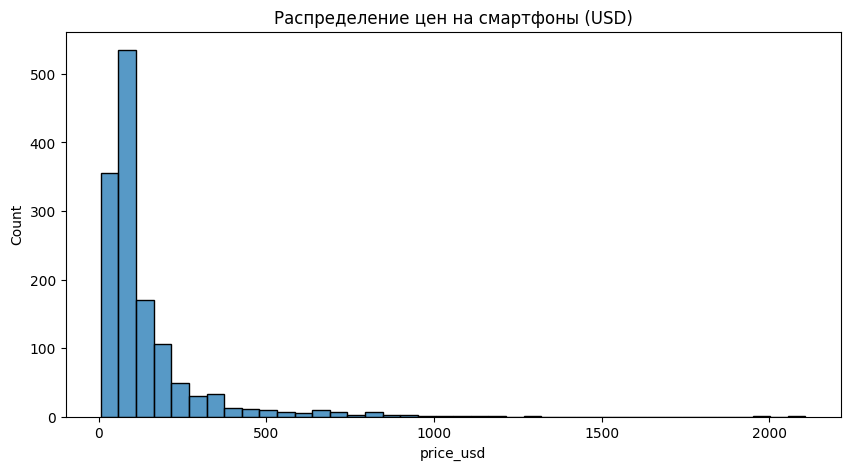

In [20]:
plt.figure(figsize=(10,5))
sns.histplot(df['price_usd'], bins=40)
plt.title("Распределение цен на смартфоны (USD)")
plt.show()

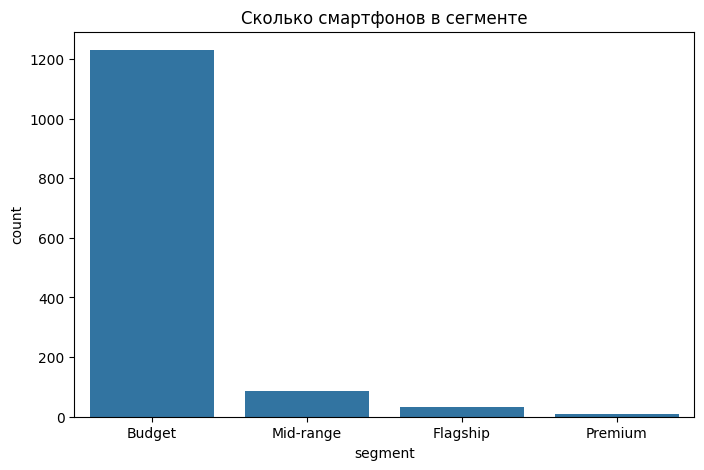

In [21]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='segment', order=['Budget','Mid-range','Flagship','Premium'])
plt.title("Сколько смартфонов в сегменте")
plt.show()

In [22]:
corr_features = [
    'price_usd',
    'ram_gb',
    'internal_storage_gb',
    'battery_capacity_mah',
    'screen_size_inches',
    'ppi',
    'rear_camera_mp',
    'front_camera_mp',
    'tech_score'
]

corr = df[corr_features].corr()
corr

,price_usd,ram_gb,internal_storage_gb,battery_capacity_mah,screen_size_inches,ppi,rear_camera_mp,front_camera_mp,tech_score
price_usd,1.000000,0.613446,0.644079,0.297525,0.402462,0.525873,0.378562,0.310439,0.584902
ram_gb,0.613446,1.000000,0.847864,0.600969,0.707088,0.642430,0.661840,0.698138,0.913961
internal_storage_gb,0.644079,0.847864,1.000000,0.483489,0.612804,0.499087,0.572862,0.613492,0.796613
battery_capacity_mah,0.297525,0.600969,0.483489,1.000000,0.746886,0.410661,0.500280,0.542818,0.798393
screen_size_inches,0.402462,0.707088,0.612804,0.746886,1.000000,0.468061,0.582596,0.654214,0.786766
ppi,0.525873,0.642430,0.499087,0.410661,0.468061,1.000000,0.478935,0.428380,0.759062
rear_camera_mp,0.378562,0.661840,0.572862,0.500280,0.582596,0.478935,1.000000,0.640290,0.753355
front_camera_mp,0.310439,0.698138,0.613492,0.542818,0.654214,0.428380,0.640290,1.000000,0.710128
tech_score,0.584902,0.913961,0.796613,0.798393,0.786766,0.759062,0.753355,0.710128,1.000000


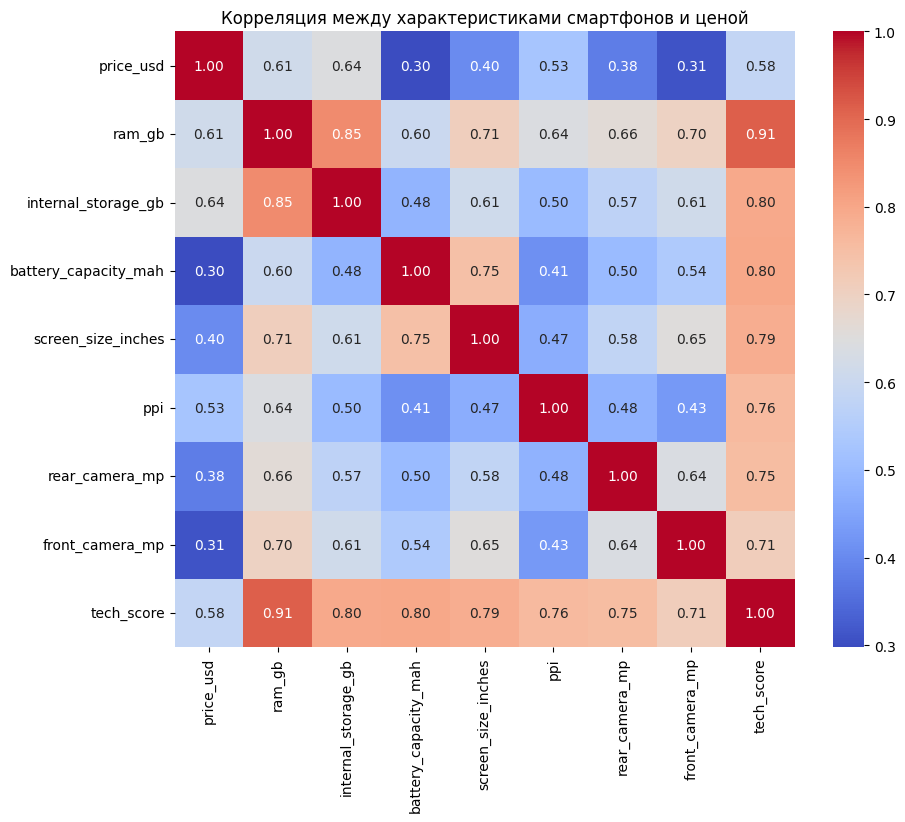

In [23]:
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Корреляция между характеристиками смартфонов и ценой")
plt.show()

In [24]:
corr['price_usd'].sort_values(ascending=False)

price_usd               1.000000
internal_storage_gb     0.644079
ram_gb                  0.613446
tech_score              0.584902
ppi                     0.525873
screen_size_inches      0.402462
rear_camera_mp          0.378562
front_camera_mp         0.310439
battery_capacity_mah    0.297525
Name: price_usd, dtype: float64

Наиболее сильное влияние на цену смартфона оказывают объем внутренней памяти и оперативной памяти.
Камера и батарея имеют заметно более слабую корреляцию с ценой, что говорит о том, что производители продают прежде всего производительность и память, а не автономность.

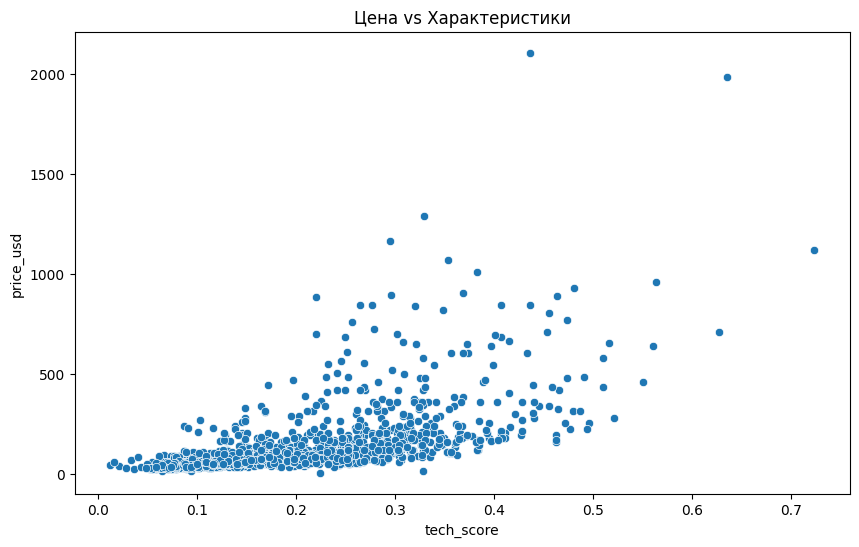

In [25]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='tech_score', y='price_usd')
plt.title("Цена vs Характеристики")
plt.show()

In [26]:
df_sorted = df.sort_values('value_score', ascending=False)
df_sorted[['brand','model','price_usd','tech_score','value_score']].head(10)

,brand,model,price_usd,tech_score,value_score
1101,Lyf,Water 7,5.951807,0.224009,0.000453
343,Gionee,A1 Plus,11.975904,0.328524,0.000331
1225,LG,K7,11.975904,0.093716,0.000094
1113,Swipe,Elite Plus,36.132530,0.237862,0.000079
549,Gionee,Marathon M3,42.048193,0.243432,0.000070
1061,Swipe,Konnect Plus,36.024096,0.192412,0.000064
400,Phicomm,Passion 660,39.012048,0.207802,0.000064
1244,ZTE,Blade A1,34.939759,0.184396,0.000064
497,Intex,Elyt e7,48.180723,0.252959,0.000063
951,iVoomi,iV505,46.987952,0.244608,0.000063


In [27]:
df_bad = df.sort_values('value_score', ascending=True)
df_bad[['brand','model','price_usd','tech_score','value_score']].head(10)

,brand,model,price_usd,tech_score,value_score
617,Samsung,Galaxy Z Flip,2108.313253,0.435771,0.000002
772,Sony,Xperia L2,883.132530,0.219544,0.000003
630,Apple,iPhone 11 Pro,1167.469880,0.294636,0.000003
2,Apple,iPhone 11 Pro Max,1287.951807,0.329536,0.000003
587,Nokia,Asha 501,60.228916,0.015661,0.000003
443,Nokia,Asha 502,42.156627,0.011725,0.000003
41,Apple,iPhone X,843.361446,0.264654,0.000004
248,Samsung,Galaxy S4,697.771084,0.219826,0.000004
651,Samsung,Galaxy Fold,1987.939759,0.634866,0.000004
22,Apple,iPhone XS Max,843.361446,0.276991,0.000004


Максимальную ценность предлагают бюджетные бренды, которые не включают значительную «наценку за бренд».

Бренд создаёт дополнительную наценку сверх характеристик.

In [28]:
top_brands = ['Apple','Samsung','Xiaomi']
df_brands = df[df['brand'].isin(top_brands)]

In [29]:
df_brands['brand'].value_counts()

brand
Samsung    101
Xiaomi      47
Apple       17
Name: count, dtype: int64

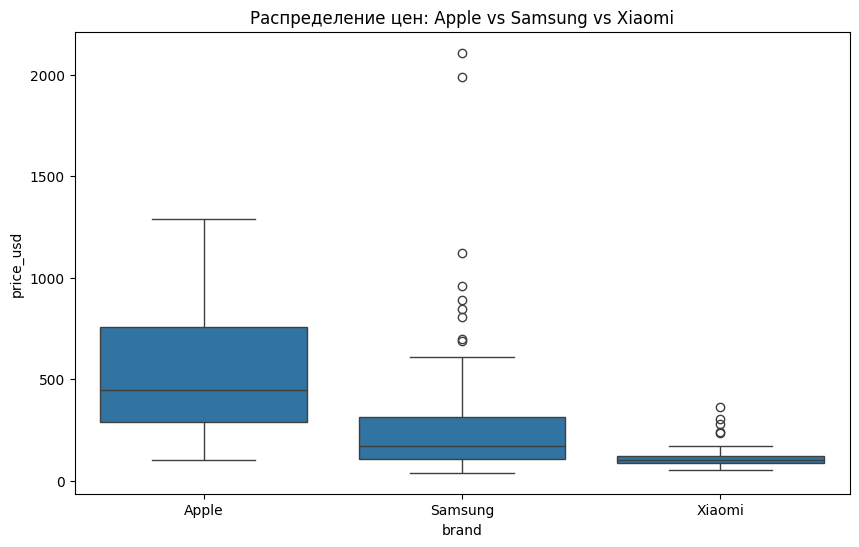

In [30]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_brands, x='brand', y='price_usd')
plt.title("Распределение цен: Apple vs Samsung vs Xiaomi")
plt.show()

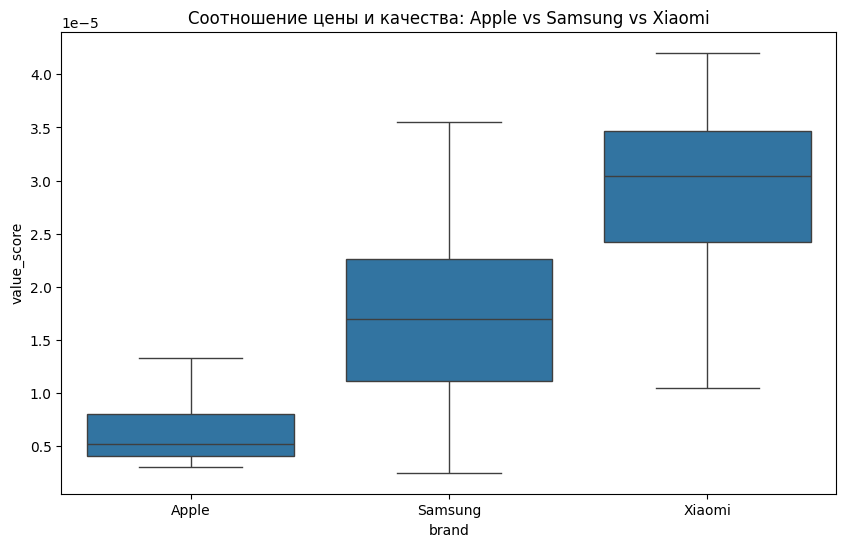

In [31]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_brands, x='brand', y='value_score')
plt.title("Соотношение цены и качества: Apple vs Samsung vs Xiaomi")
plt.show()

Apple продаёт бренд и экосистему, Xiaomi продаёт характеристики, Samsung — балансирует между ними.

In [32]:
from scipy.stats import f_oneway

apple_prices = df[df['brand']=='Apple']['price_usd']
samsung_prices = df[df['brand']=='Samsung']['price_usd']
xiaomi_prices = df[df['brand']=='Xiaomi']['price_usd']

In [33]:
f_stat, p_value = f_oneway(apple_prices, samsung_prices, xiaomi_prices)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 14.60114871131208
p-value: 1.4783408137705237e-06


Бренд статистически значимо влияет на цену смартфона.
Разница в стоимости между Apple, Samsung и Xiaomi не случайна и подтверждена ANOVA-тестом.

In [34]:
final_df = df[[
    'brand',
    'model',
    'price_usd',
    'segment',
    'ram_gb',
    'internal_storage_gb',
    'battery_capacity_mah',
    'ppi',
    'rear_camera_mp',
    'tech_score',
    'value_score'
]]

In [35]:
final_df.head()

,brand,model,price_usd,segment,ram_gb,internal_storage_gb,battery_capacity_mah,ppi,rear_camera_mp,tech_score,value_score
0,OnePlus,7T Pro McLaren Edition,710.819277,Flagship,11.718750,256.0,4085,515.183966,48,0.627552,0.000011
1,Realme,X2 Pro,337.337349,Mid-range,5.859375,64.0,4000,404.893148,64,0.445602,0.000016
2,Apple,iPhone 11 Pro Max,1287.951807,Premium,3.906250,64.0,3969,455.548515,12,0.329536,0.000003
3,Apple,iPhone 11,757.831325,Flagship,3.906250,64.0,3110,323.613699,12,0.256077,0.000004
4,LG,G8X ThinQ,602.289157,Flagship,5.859375,128.0,4000,402.688717,12,0.373656,0.000007


In [36]:
final_df.to_csv("cleaned_smartphone_data.csv", index=False)